In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import seaborn as sns 

In [2]:
metric_4_path = Path("metric_4_regular_agents.csv")
result = Path("results/py/day_night_flights.png")
result.parent.mkdir(parents=True, exist_ok=True)
metric_4 = pd.read_csv(metric_4_path)

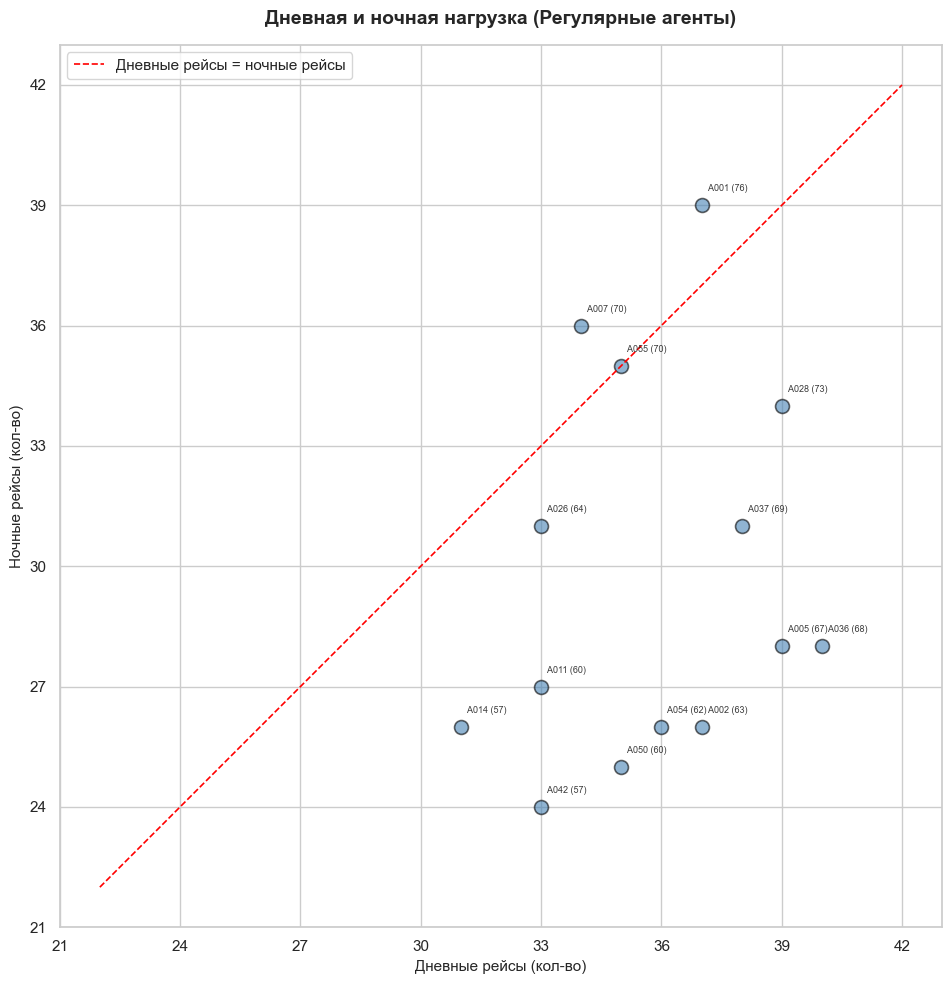

In [3]:
sns.set_theme(style = "whitegrid")
plt.figure(figsize = (10, 10))

sns.scatterplot(
    data = metric_4,
    x = 'day_flights',
    y = 'night_flights',
    s = 100,
    color = 'steelblue',
    edgecolor = 'black',
    linewidth = 1.2,
    alpha = 0.6
    )
axis_max = max(metric_4['day_flights'].max(), metric_4['night_flights'].max())
axis_min = min(metric_4['day_flights'].min(), metric_4['night_flights'].min())

plt.plot(
    [axis_min - 2, axis_max + 2],
    [axis_min - 2, axis_max + 2],
    color = 'red', linestyle = '--', linewidth = 1.2, label = 'Дневные рейсы = ночные рейсы'
)

for _, row in metric_4.iterrows():
    total = row['day_flights'] + row['night_flights']
    label = f" {row['agent_name']} ({total})"

    plt.text(
        row['day_flights'] + 0.1,
        row['night_flights'] + 0.3,
        label,
        fontsize=6.5,
        alpha=0.9,
        verticalalignment='bottom',
        horizontalalignment='left'
    )

plt.title('Дневная и ночная нагрузка (Регулярные агенты)', fontsize=14, pad=15, fontweight='bold')
plt.xlabel('Дневные рейсы (кол-во)', fontsize=11)
plt.ylabel('Ночные рейсы (кол-во)', fontsize=11)

plt.xlim(axis_min - 3, axis_max + 3)
plt.ylim(axis_min - 3, axis_max + 3)
plt.gca().set_aspect('equal', adjustable='box')
plt.gca().xaxis.set_major_locator(MaxNLocator(integer=True))
plt.gca().yaxis.set_major_locator(MaxNLocator(integer=True))

plt.legend(loc='upper left')
plt.tight_layout()

plt.savefig(result, dpi=150, bbox_inches='tight')
plt.show()